NEURAL NETWROK IMPLEMENTATION


In [2]:
import numpy as np 
import pandas as pd
from matplotlib import pyplot as plt


In [3]:
data = pd.read_csv("mnist_train.csv")


In [4]:
data = np.array(data)
m,n = data.shape
np.random.shuffle(data)


In [ ]:
m,n


(60000, 785)

In [18]:
train_data = data[:int(m*0.8),:]
test_data = data[int(m*0.8):m,:]

X_train = train_data[:,1:].T
X_train = X_train/255.0
y_train = train_data[:,0]

X_val = test_data[:,1:].T
X_val = X_val/255.0 
y_val = test_data[:,0]


In [19]:
X_train.shape,y_train.shape,X_val.shape,y_val.shape

((784, 48000), (48000,), (784, 12000), (12000,))

In [24]:
def initialize_parameters():
    W1 = np.random.rand(10,784) - 0.5
    B1 = np.random.rand(10,1) - 0.5
    W2 = np.random.rand(10,10) - 0.5
    B2 = np.random.rand(10,1) - 0.5
    return W1, B1 , W2 , B2

def RelU(Z):
    return np.maximum(0,Z)
def softmax_calculator(Z):
    return np.exp(Z)/sum(np.exp(Z))

def forward_propagation(W1,B1,W2,B2,X):
    Z1 = W1.dot(X) + B1
    A1 = RelU(Z1)
    Z2 = W2.dot(A1) + B2
    A2 = softmax_calculator(Z2)
    return Z1,A1,Z2,A2
def one_hot_enocoder(Y):
    one_hot_Y = np.zeros((Y.size,Y.max() +1))
    one_hot_Y[np.arange(Y.size),Y] = 1
    return one_hot_Y.T

def backward_propagation(W1,B1,W2,B2,Z1,A1,Z2,A2,X,Y):
    one_hot_Y = one_hot_enocoder(Y)
    dZ2 =  A2 - one_hot_Y
    dW2 = (1/m) * dZ2.dot(A1.T)
    db2 = (1/m) * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2) * (Z1 > 0)
    dW1 = (1/m) * dZ1.dot(X.T)
    db1 = (1/m) * np.sum(dZ1)
    return dW1, db1, dW2, db2, dZ1,dZ2

def update_parameters(W1,B1,W2,B2,dW1,dB1,dW2,dB2,learning_rate = 0.01):
    W1 = W1 - learning_rate * dW1
    B1 = B1 - learning_rate * dB1   
    W2 = W2 - learning_rate * dW2
    B2 = B2 - learning_rate * dB2

    return W1,B1,W2,B2

def get_predictions(A2):
    return np.argmax(A2,0)
def get_accuracy(predictions,Y):
    return np.sum(predictions == Y)/Y.size
def gradient_descent(X,Y,epochs = 1000,learning_rate = 0.01):
    W1,B1,W2,B2 = initialize_parameters()
    for i in range(epochs):
        Z1,A1,Z2,A2 = forward_propagation(W1,B1,W2,B2,X)
        dW1,dB1,dW2,dB2,dZ1,dZ2 = backward_propagation(W1,B1,W2,B2,Z1,A1,Z2,A2,X,Y)
        W1,B1,W2,B2 = update_parameters(W1,B1,W2,B2,dW1,dB1,dW2,dB2,learning_rate)
        if i % 100 == 0:
            print("Epochs: ",i)
            print("accuracy: ",get_accuracy(get_predictions(A2),Y))
    return W1,B1,W2,B2

In [26]:
W1,B1,W2,B2 = gradient_descent(X_train,y_train,epochs = 1000,learning_rate = 0.1)

Epochs:  0
accuracy:  0.097125
Epochs:  100
accuracy:  0.57625
Epochs:  200
accuracy:  0.7370416666666667
Epochs:  300
accuracy:  0.7892916666666666
Epochs:  400
accuracy:  0.81775
Epochs:  500
accuracy:  0.8358125
Epochs:  600
accuracy:  0.84875
Epochs:  700
accuracy:  0.8576041666666666
Epochs:  800
accuracy:  0.8641666666666666
Epochs:  900
accuracy:  0.8692708333333333


Predicted:  [3]
Actual:  3


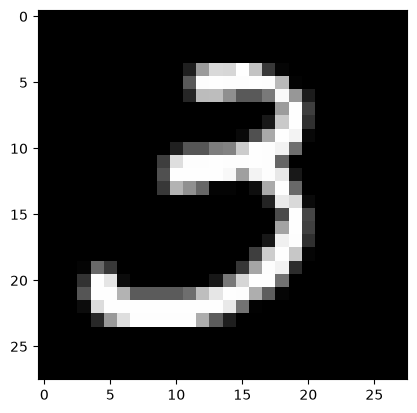

In [39]:
val_index = 112
Z1,A1,Z2,A2 = forward_propagation(W1,B1,W2,B2,X_val[:,val_index,None])
print("Predicted: ",get_predictions(A2))
print("Actual: ",y_val[val_index])

image_array = X_val[:,val_index].reshape((28,28)) 
plt.imshow(image_array,cmap = "gray")